In [32]:
import json
import pathlib
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display as ipy_display, Image as IPyImage

BASE    = pathlib.Path(r'D:/ultrasam2-results')
STATS   = BASE / 'checkpoints' / 'checkpoint2.2'
OUT_DIR = pathlib.Path('.')

def load_jsonl(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows

def dedup(rows, epoch_key='Trainer/epoch'):
    """Keep the last row per epoch (second session overwrites first where they overlap)."""
    seen = {}
    for r in rows:
        seen[r[epoch_key]] = r
    return [seen[e] for e in sorted(seen)]

train = dedup(load_jsonl(STATS / 'train_stats.json'))
val   = dedup(load_jsonl(STATS / 'val_stats.json'))

t_epoch = np.array([r['Trainer/epoch'] for r in train])
v_epoch = np.array([r['Trainer/epoch'] for r in val])

t = {k: np.array([r[k] for r in train]) for k in train[0] if k.startswith('Losses/')}
v = {k: np.array([r[k] for r in val])   for k in val[0]   if k.startswith('Losses/')}

common = np.intersect1d(t_epoch, v_epoch)
ti = np.isin(t_epoch, common)
vi = np.isin(v_epoch, common)

print(f'Train epochs: {t_epoch[0]}–{t_epoch[-1]}  ({len(t_epoch)} rows)')
print(f'Test  epochs: {v_epoch[0]}–{v_epoch[-1]}  ({len(v_epoch)} rows)')

Train epochs: 0–39  (40 rows)
Test  epochs: 0–39  (40 rows)


# UltraSAM2 — Training Curves

## Loss Guide

UltraSAM2 inherits SAM2's training objective unchanged. At each prediction step the model outputs up to three candidate masks; the best candidate (lowest combined mask+dice loss) is selected for back-propagation. Losses are normalised by the number of objects in the batch and accumulated across all prediction steps.

The **core loss** (what is plotted as "total") is a weighted sum:

`core = 20 · mask + 1 · dice + 1 · iou + 1 · class`

### Mask loss (focal loss, weight 20)
Sigmoid focal loss between the predicted mask logits and the binary ground-truth mask. The focal modulation `(1 − p_t)^γ` down-weights easy (well-classified) pixels so the network focuses on hard boundary regions. Dominates the total by design — SAM2's original recipe uses 20× to ensure mask quality drives optimisation. Lower is better.

### Dice loss (weight 1)
Soft Dice between the predicted and ground-truth masks: `1 − (2·|P∩GT| + 1) / (|P| + |GT| + 1)`. Measures overlap as a ratio, so it is scale-invariant and handles class imbalance well. Complements the focal loss, which operates pixel-wise. Lower is better.

### IoU loss (weight 1)
L1 loss between the **predicted IoU score** (a scalar the model outputs alongside each mask) and the **actual IoU** computed from the thresholded prediction vs ground truth. Trains the model's confidence calibration — its IoU head should accurately predict how good its own mask is. Lower is better.

### Class loss (weight 1)
Focal loss on the **object presence score** — whether an object exists in the frame at all. Enables the model to predict "no object" rather than always outputting a mask. Typically near zero once the model learns the training data contains objects. Lower is better.

## Total loss — train vs test

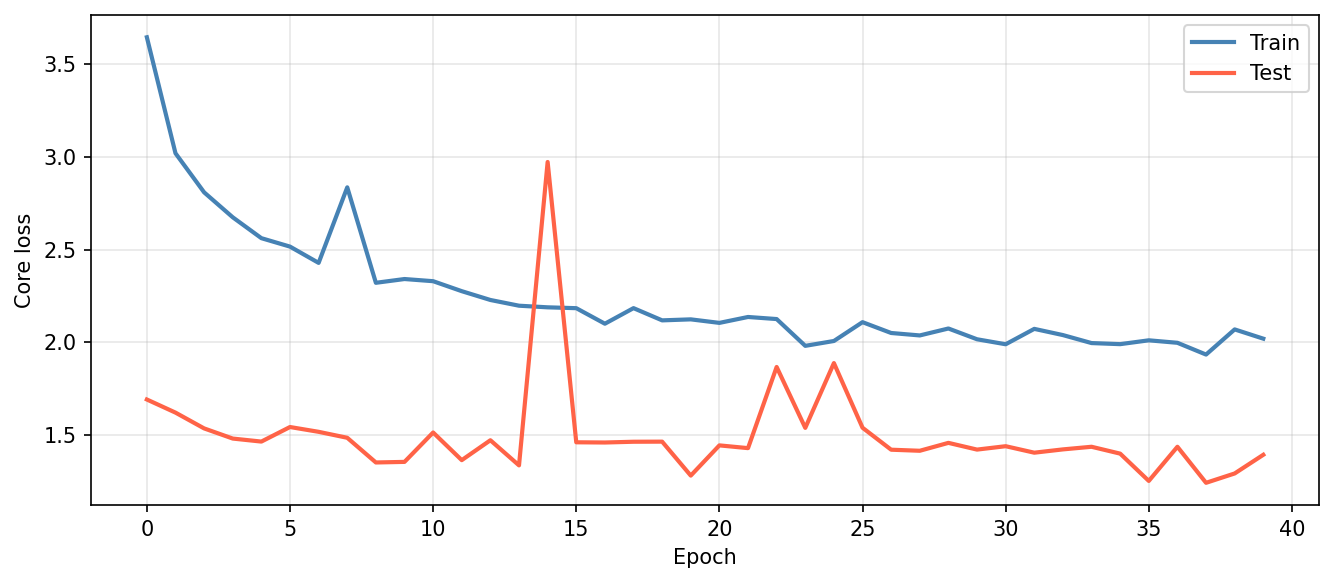

Saved → ultrasam2_loss_total.png


In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_epoch, t['Losses/train_all_core_loss'], label='Train', color='steelblue', lw=2)
ax.plot(v_epoch, v['Losses/val_val_core_loss'],   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Core loss')
#ax.set_title('UltraSAM2 — Total loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = OUT_DIR / 'ultrasam2_loss_total.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=str(out)))
print(f'Saved → {out}')

## Dice loss — train vs test

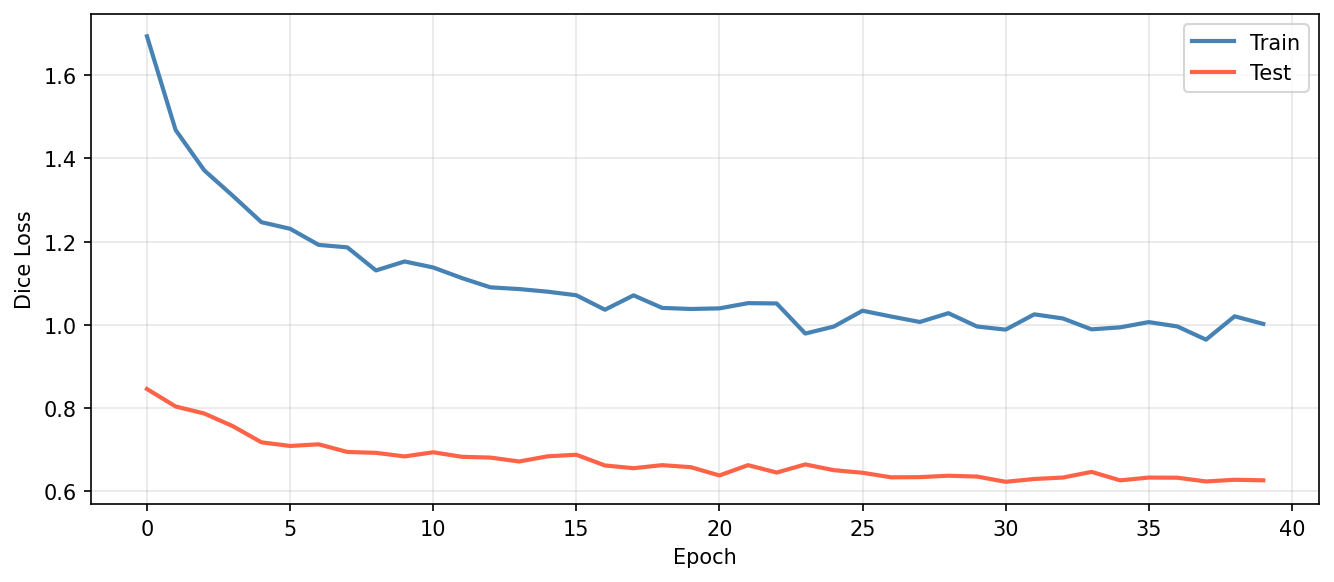

Saved → ultrasam2_loss_dice.png


In [34]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_epoch, t['Losses/train_all_loss_dice'], label='Train', color='steelblue', lw=2)
ax.plot(v_epoch, v['Losses/val_val_loss_dice'],   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Dice Loss')
#ax.set_title('UltraSAM2 — Dice loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = OUT_DIR / 'ultrasam2_loss_dice.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=str(out)))
print(f'Saved → {out}')

## IoU loss — train vs test

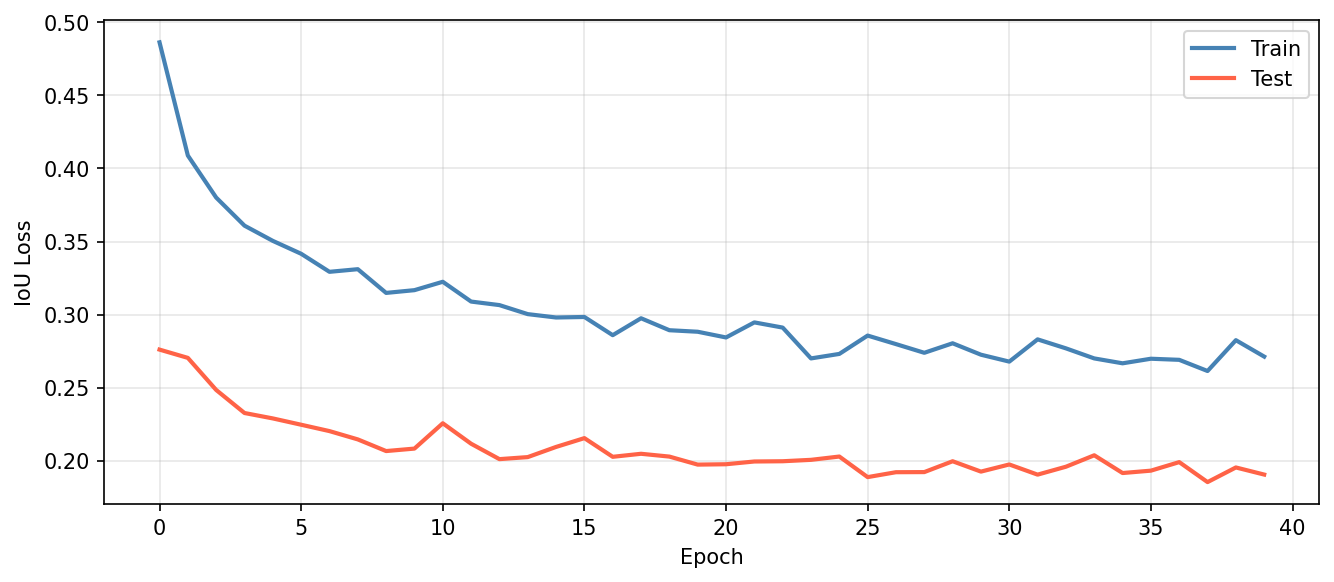

Saved → ultrasam2_loss_iou.png


In [35]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_epoch, t['Losses/train_all_loss_iou'], label='Train', color='steelblue', lw=2)
ax.plot(v_epoch, v['Losses/val_val_loss_iou'],   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('IoU Loss')
#ax.set_title('UltraSAM2 — IoU loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = OUT_DIR / 'ultrasam2_loss_iou.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=str(out)))
print(f'Saved → {out}')

## Mask loss — train vs test

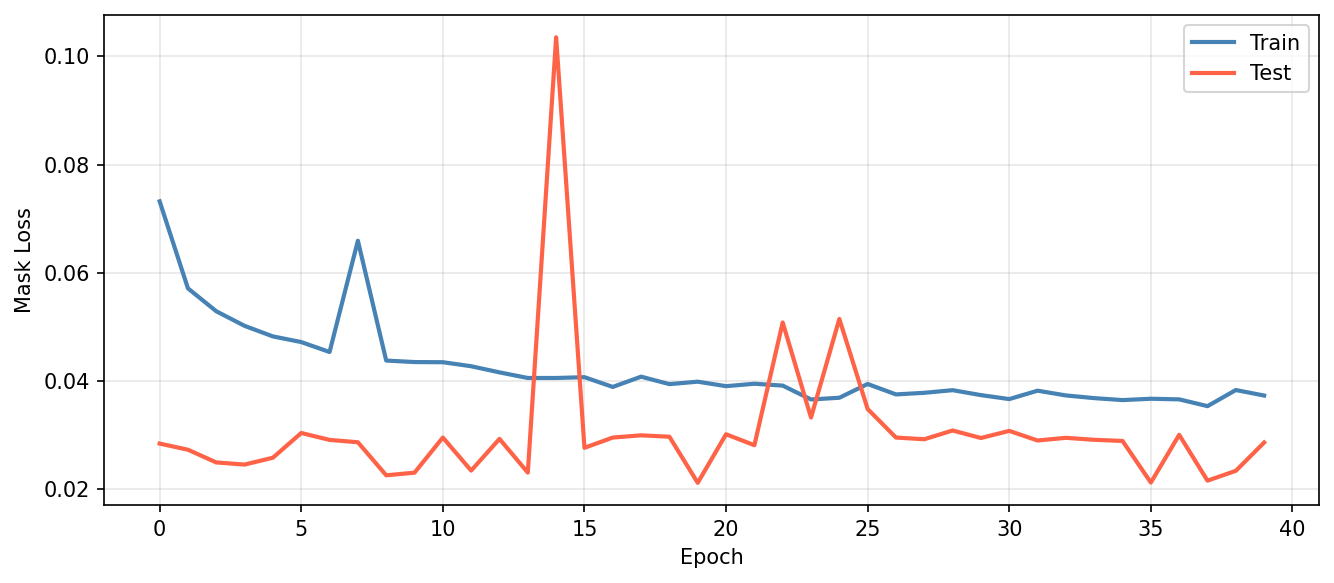

Saved → ultrasam2_loss_mask.png


In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_epoch, t['Losses/train_all_loss_mask'], label='Train', color='steelblue', lw=2)
ax.plot(v_epoch, v['Losses/val_val_loss_mask'],   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Mask Loss')
#ax.set_title('UltraSAM2 — Mask loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = OUT_DIR / 'ultrasam2_loss_mask.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=str(out)))
print(f'Saved → {out}')

## Class loss — train vs test

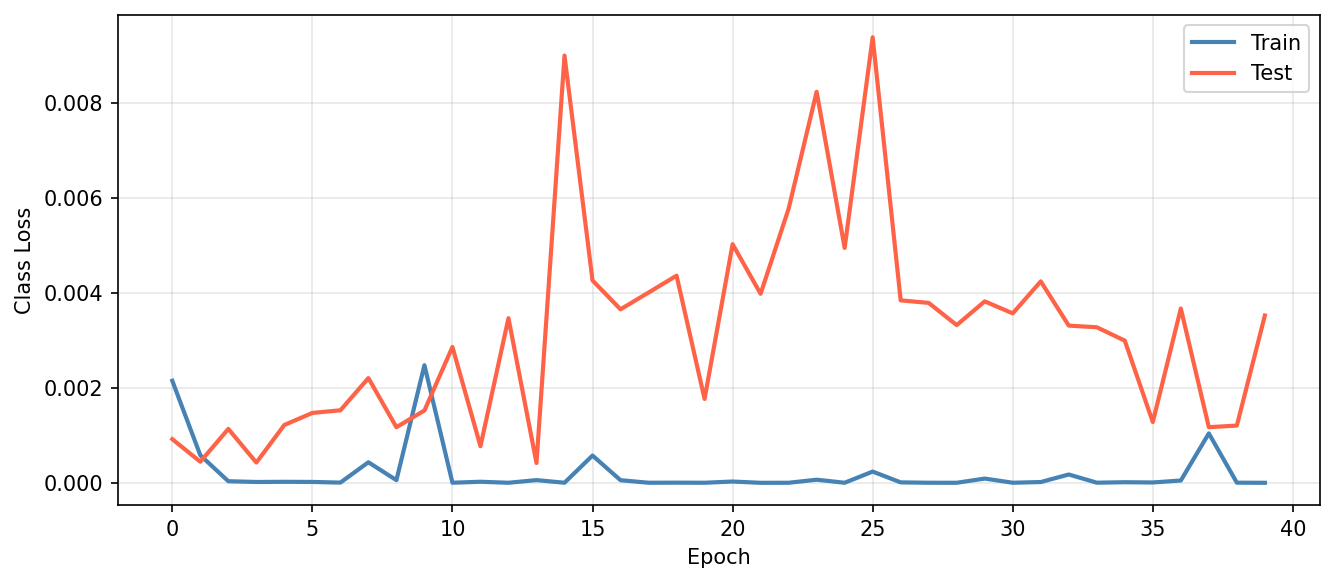

Saved → ultrasam2_loss_class.png


In [37]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_epoch, t['Losses/train_all_loss_class'], label='Train', color='steelblue', lw=2)
ax.plot(v_epoch, v['Losses/val_val_loss_class'],   label='Test',  color='tomato',    lw=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Class Loss')
#ax.set_title('UltraSAM2 — Class loss')
ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = OUT_DIR / 'ultrasam2_loss_class.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=str(out)))
print(f'Saved → {out}')

## Train − Test gap (total loss)

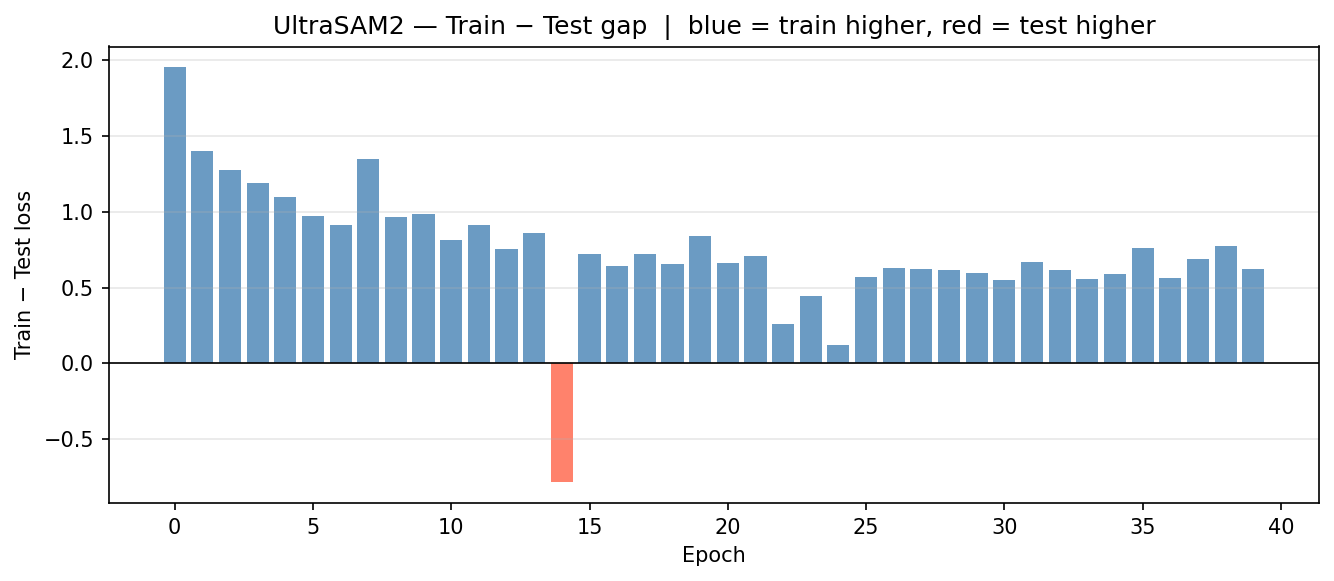

Saved → ultrasam2_train_test_gap.png


In [38]:
gap = t['Losses/train_all_core_loss'][ti] - v['Losses/val_val_core_loss'][vi]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(common, gap, color=np.where(gap >= 0, 'steelblue', 'tomato'), alpha=0.8)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Epoch')
ax.set_ylabel('Train − Test loss')
ax.set_title('UltraSAM2 — Train − Test gap  |  blue = train higher, red = test higher')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, alpha=0.3, axis='y')
fig.tight_layout()
out = OUT_DIR / 'ultrasam2_train_test_gap.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=str(out)))
print(f'Saved → {out}')

## Summary

In [39]:
best_vi        = np.argmin(v['Losses/val_val_core_loss'])
best_val_epoch = v_epoch[best_vi]
best_val_loss  = v['Losses/val_val_core_loss'][best_vi]

print(f'Epochs completed : {len(t_epoch)}')
print(f'Best test loss   : {best_val_loss:.4f}  (epoch {best_val_epoch})')
print(f'Last train loss  : {t["Losses/train_all_core_loss"][-1]:.4f}')
print(f'Last test loss   : {v["Losses/val_val_core_loss"][-1]:.4f}')
print()
print('Component breakdown at best test epoch:')
for key, label in [('loss_dice','Dice'),('loss_iou','IoU'),('loss_mask','Mask'),('loss_class','Class')]:
    tv = t[f'Losses/train_all_{key}'][np.where(t_epoch == best_val_epoch)[0][0]]
    vv = v[f'Losses/val_val_{key}'][best_vi]
    print(f'  {label:6s}  train={tv:.4f}  test={vv:.4f}')

Epochs completed : 40
Best test loss   : 1.2409  (epoch 37)
Last train loss  : 2.0189
Last test loss   : 1.3922

Component breakdown at best test epoch:
  Dice    train=0.9641  test=0.6233
  IoU     train=0.2614  test=0.1854
  Mask    train=0.0353  test=0.0216
  Class   train=0.0011  test=0.0012
